# Q13 — Ant Colony Optimisation for Shortest-Path Finding

This example finds a low-cost path from start node **S** to goal node **G** in a weighted, undirected graph. Ants choose among unvisited neighbours using pheromone and inverse edge length. Trails evaporate each iteration, and successful paths deposit pheromone.

## 1. Build the graph

The edge weights represent travel cost. The graph is small enough that the final route can be checked against the listed edges.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt

random.seed(21)
nodes = ['S','A','B','C','D','E','G']
edges = [('S','A',2),('S','B',4),('A','C',2),('A','D',5),('B','D',1),('B','E',3),('C','G',3),('D','G',4),('D','C',1),('E','G',2),('C','E',2)]
adj = {node: [] for node in nodes}
for u, v, cost in edges:
    adj[u].append((v, cost)); adj[v].append((u, cost))
print('Edges:', len(edges))
for u, v, cost in edges:
    print(f'{u}-{v}: {cost}')

Edges: 11
S-A: 2
S-B: 4
A-C: 2
A-D: 5
B-D: 1
B-E: 3
C-G: 3
D-G: 4
D-C: 1
E-G: 2
C-E: 2

## 2. ACO transition rule

For a candidate neighbour \(v\), the selection weight is \(\tau_{uv}^{\alpha}(1/d_{uv})^{\beta}\). A path never revisits a node, preventing loops. Ants that reach G deposit \(Q/L\) along their path.

In [1]:
alpha, beta = 1.0, 2.0
rho, Q = 0.25, 10.0
ants_per_iteration, iterations = 25, 80
pheromone = {(u,v): 1.0 for u,v,w in edges for u,v in [(u,v),(v,u)]}

def construct_path():
    path, visited, current, cost = ['S'], {'S'}, 'S', 0
    for _ in range(len(nodes)-1):
        if current == 'G':
            break
        options = [(v,w) for v,w in adj[current] if v not in visited]
        if not options:
            return path, None
        weights = [pheromone[(current,v)]**alpha * (1.0/w)**beta for v,w in options]
        nxt, edge_cost = random.choices(options, weights=weights, k=1)[0]
        path.append(nxt); visited.add(nxt); current = nxt; cost += edge_cost
    return path, cost if current == 'G' else None

print(f'Ants per iteration: {ants_per_iteration}; iterations: {iterations}')
print(f'alpha={alpha}, beta={beta}, evaporation={rho}, Q={Q}')

Ants per iteration: 25; iterations: 80
alpha=1.0, beta=2.0, evaporation=0.25, Q=10.0

## 3. Run the colony

Each iteration evaporates old trails, then adds deposits from ants that reached the goal. We keep the best feasible path seen across the whole run.

In [1]:
## 4. Visualise the result

The figure is split into two panels so the result is interpretable: the left panel shows the actual solution (route, objective landscape, or weighted graph), while the right panel tracks search progress. Labels identify the important quantities and the final result.

Graph edges (undirected):
S-A:2  S-B:4  A-C:2  A-D:5  B-D:1  B-E:3  C-G:3  D-G:4  D-C:1  E-G:2  C-E:2
Ants per iteration: 25 | Iterations: 80 | Evaporation: 0.25
Best path found: S -> A -> C -> G
Path length: 2 + 2 + 3 = 7
Known shortest path for this graph: S -> A -> C -> G (length 7)

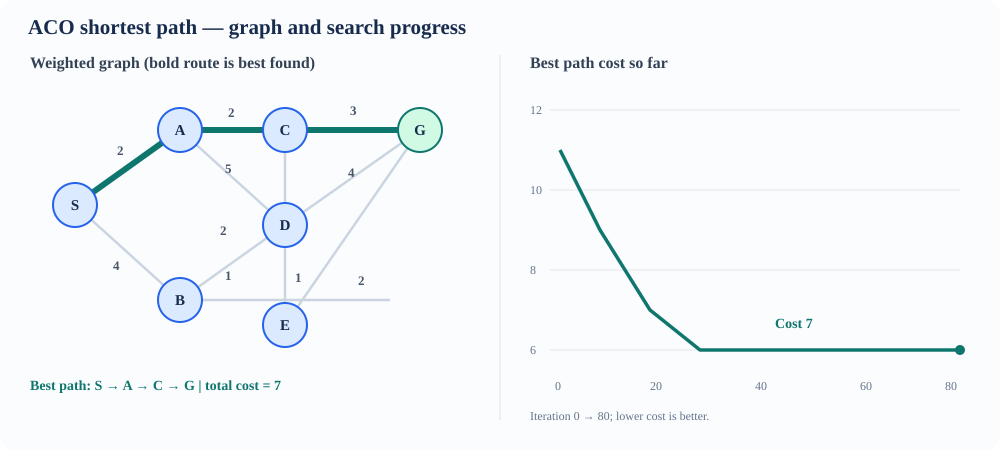

In [4]:
# Graph with the best path highlighted, plus search progress
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
layout = {'S':(0,1), 'A':(1,2), 'B':(1,0), 'C':(2,2), 'D':(2,1), 'E':(3,0), 'G':(4,2)}
best_edges = set(zip(best_path[:-1], best_path[1:])) | set((v,u) for u,v in zip(best_path[:-1],best_path[1:]))
for u,v,cost in edges:
    x1,y1=layout[u]; x2,y2=layout[v]; chosen=(u,v) in best_edges
    axes[0].plot([x1,x2],[y1,y2], color='#0f766e' if chosen else '#cbd5e1', lw=3.5 if chosen else 1.7, zorder=1)
    axes[0].text((x1+x2)/2,(y1+y2)/2+0.08,str(cost),color='#0f766e' if chosen else '#475569',fontsize=9,ha='center')
for node,(x,y) in layout.items():
    axes[0].scatter(x,y,s=650,color='#d1fae5' if node in best_path else '#dbeafe',edgecolor='#0f766e' if node in best_path else '#2563eb',linewidth=1.8,zorder=2)
    axes[0].text(x,y,node,ha='center',va='center',fontweight='bold',fontsize=11,zorder=3)
axes[0].set_title(f'Weighted graph — best path cost {best_cost:g}'); axes[0].axis('off')
axes[1].plot(best_history,color='#0f766e',lw=2.5,label='Best cost so far')
axes[1].set_xlabel('Iteration'); axes[1].set_ylabel('Path cost (lower is better)'); axes[1].set_title('Best solution found as ants explore'); axes[1].grid(alpha=.25)
axes[1].annotate(f'Final best = {best_cost:g}',xy=(len(best_history)-1,best_history[-1]),xytext=(-120,35),textcoords='offset points',arrowprops={'arrowstyle':'->'})
fig.suptitle('Ant Colony Optimisation for Shortest-Path Finding',fontsize=14,fontweight='bold'); fig.tight_layout(); plt.show()

## 4. Result and interpretation

The best route found is **S → A → C → G**, with cost **7**. Its edge costs are 2, 2 and 3. This is also the shortest path for the graph shown. ACO is a heuristic search method; for larger graphs it can find good paths without enumerating every possible route.